This notebook includes the steps of ***Exploratory Data Analysis*** as below on this dataset based on CRISP_DM framework: 
https://www.census.gov/econ/bfs/index.html

(dataset is the U.S. Census Bureau's weekly Business Formation Statistics (BFS))
Phase 1: Business Understanding 
Phase 2: Data Understanding
    1. Dataset Structure and data types
Phase 3: Data Preparation
    1. Missing values and duplicates
    2. Outlier Detection
Phase 4: Modeling/Analysis
    1. Descriptive Statistics
    2. Skewness and Histograms
    3. Correlation map
    4. Feature Relationships
    5. Temporal Trends
Phase 5: Evaluation

Based on the documentation of the dataset (https://www.census.gov/econ/bfs/definitions.html) these identifiers mean as below:
- BA: Business Application
- HBA: High-Propensity Business Applications
- WBA: Business Applications with Planned Wages
- CBA: Corporate Business Applications

 p.n: NSA means Not Seasonally Adjusted. YY shows year over year changes.

***Phase 1: Business Understanding***

We are going to explore how U.S. business application activity changed from 2006 to 2026 using weekly Business Formation Statistics. The measures are not seasonally adjusted (NSA), so recurring calendar effects may influence the weekly counts.

Why these questions matter?
 
 A surge in business applications does not necessarily mean a comparable rise in businesses likely to hire workers. Comparing total applications with high-propensity, planned-wage, and corporate applications can help policymakers, economists, and business stakeholders understand whether the post-2020 increase reflects broader entrepreneurial interest or also growth in applications associated with potential employer businesses. These measures describe applications, not confirmed business openings or jobs created.

Question 1: How did `BA_NSA` change after 2020?

Question 2: Did `HBA_NSA` grow proportionally with `BA_NSA`?

Question 3: How strongly are `WBA_NSA` and `CBA_NSA` related?

Question 4: Are `BA_NSA`,`HBA_NSA`,`WBA_NSA` and `CBA_NSA` correlated strongly?

Question 5: What long-term trends and recurring weekly patterns appear in these four business application indicators between 2006 and 2026?


***Phase 2: Data Understanding***

***Dataset Structure and data types***

The objective of this step is to understand what the dataset contains and what are the datatypes and whether they are appropriate for the analysis.

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dataset = "bfs_us_apps_weekly_nsa.csv"
df = pd.read_csv(dataset)


In [17]:
df.head()

,Year,Week,BA_NSA,HBA_NSA,WBA_NSA,CBA_NSA,YY_BA_NSA,YY_HBA_NSA,YY_WBA_NSA,YY_CBA_NSA
0,2006,1,39250,23240,14950,12790,NaN,NaN,NaN,NaN
1,2006,2,36820,23820,15810,14410,NaN,NaN,NaN,NaN
2,2006,3,62920,38330,24430,21690,NaN,NaN,NaN,NaN
3,2006,4,51520,31460,20260,17260,NaN,NaN,NaN,NaN
4,2006,5,60890,36520,22800,19900,NaN,NaN,NaN,NaN


The dataset has 1082 weekly rows and 10 columns, including `Year`, `Week`, application counts, and year-over-year change fields. It includes 2 temporal and 8 numerical identifiers.
- `Year` and `BA_NSA` let us compare total Business Applications before and after 2020; `Week` helps track the observations within each year.
- `BA_NSA` and `HBA_NSA` , together with `Year`, allow comparison of their trends.
- `WBA_NSA` and `CBA_NSA` are used for scatterplots and correlation analysis for answering question 3.
- `BA_NSA`, `HBA_NSA`, `WBA_NSA`, and `CBA_NSA` will be compared through a correlation matrix and pairplots to answer question4.
- `Year`, `Week`, and the four application-count columns are needed to investigate changes over time and recurring reporting-week patterns.

In [20]:
df.shape

(1082, 10)

In [21]:
df.nunique()

Year           21
Week           53
BA_NSA        998
HBA_NSA       842
WBA_NSA       626
CBA_NSA       583
YY_BA_NSA     925
YY_HBA_NSA    902
YY_WBA_NSA    922
YY_CBA_NSA    898
dtype: int64

In [97]:
df["Year"].min(), df["Year"].max()

(np.int64(2006), np.int64(2026))

Based on these results, the dataset includes the data from 2006 to 2026.

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1082 entries, 0 to 1081
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        1082 non-null   int64  
 1   Week        1082 non-null   int64  
 2   BA_NSA      1082 non-null   int64  
 3   HBA_NSA     1082 non-null   int64  
 4   WBA_NSA     1082 non-null   int64  
 5   CBA_NSA     1082 non-null   int64  
 6   YY_BA_NSA   1027 non-null   float64
 7   YY_HBA_NSA  1027 non-null   float64
 8   YY_WBA_NSA  1027 non-null   float64
 9   YY_CBA_NSA  1027 non-null   float64
dtypes: float64(4), int64(6)
memory usage: 84.7 KB


In [ ]:
coverage = df.groupby("Year")["Week"].agg(observations="count")
display(coverage)

,observations
Year,
2006,52
2007,52
2008,53
2009,52
2010,52
2011,52
2012,52
2013,52
2014,53


Out of 2026, 39 weeks are included, which is 75% of the year. The other years have full coverage of 52 weeks.

***Phase 3: Data Preparation***

Missing Values

In [26]:
df.isnull().sum()

Year           0
Week           0
BA_NSA         0
HBA_NSA        0
WBA_NSA        0
CBA_NSA        0
YY_BA_NSA     55
YY_HBA_NSA    55
YY_WBA_NSA    55
YY_CBA_NSA    55
dtype: int64

All four original business application indicators have zero missing values. About the annual changes, as the data of 2005 does not exist in the dataset, the first year of the dataset (2006) has missing values for each of the 4 related features.

In [65]:
yy_cols = [
    "YY_BA_NSA",
    "YY_HBA_NSA",
    "YY_WBA_NSA",
    "YY_CBA_NSA"
]

missing_rows = df[df[yy_cols].isna().any(axis=1)]

missing_rows.groupby("Year")["Week"].agg(["count", "min", "max"])

,count,min,max
Year,,,
2006,52,1,52
2008,1,53,53
2014,1,53,53
2025,1,53,53


Duplicate Values

In [30]:
df.duplicated().sum()

np.int64(0)

Check for probabale duplicates based on Year and Week columns

In [66]:
df.duplicated(subset=["Year", "Week"]).sum()

np.int64(0)

The dataset contains no missing values in its four original business application indicators and no exact duplicate records. Each of the four year-over-year variables contains 55 missing observations. These missing values are consistent with the expected limitations of year-over-year calculations.

***Outlier Detection***

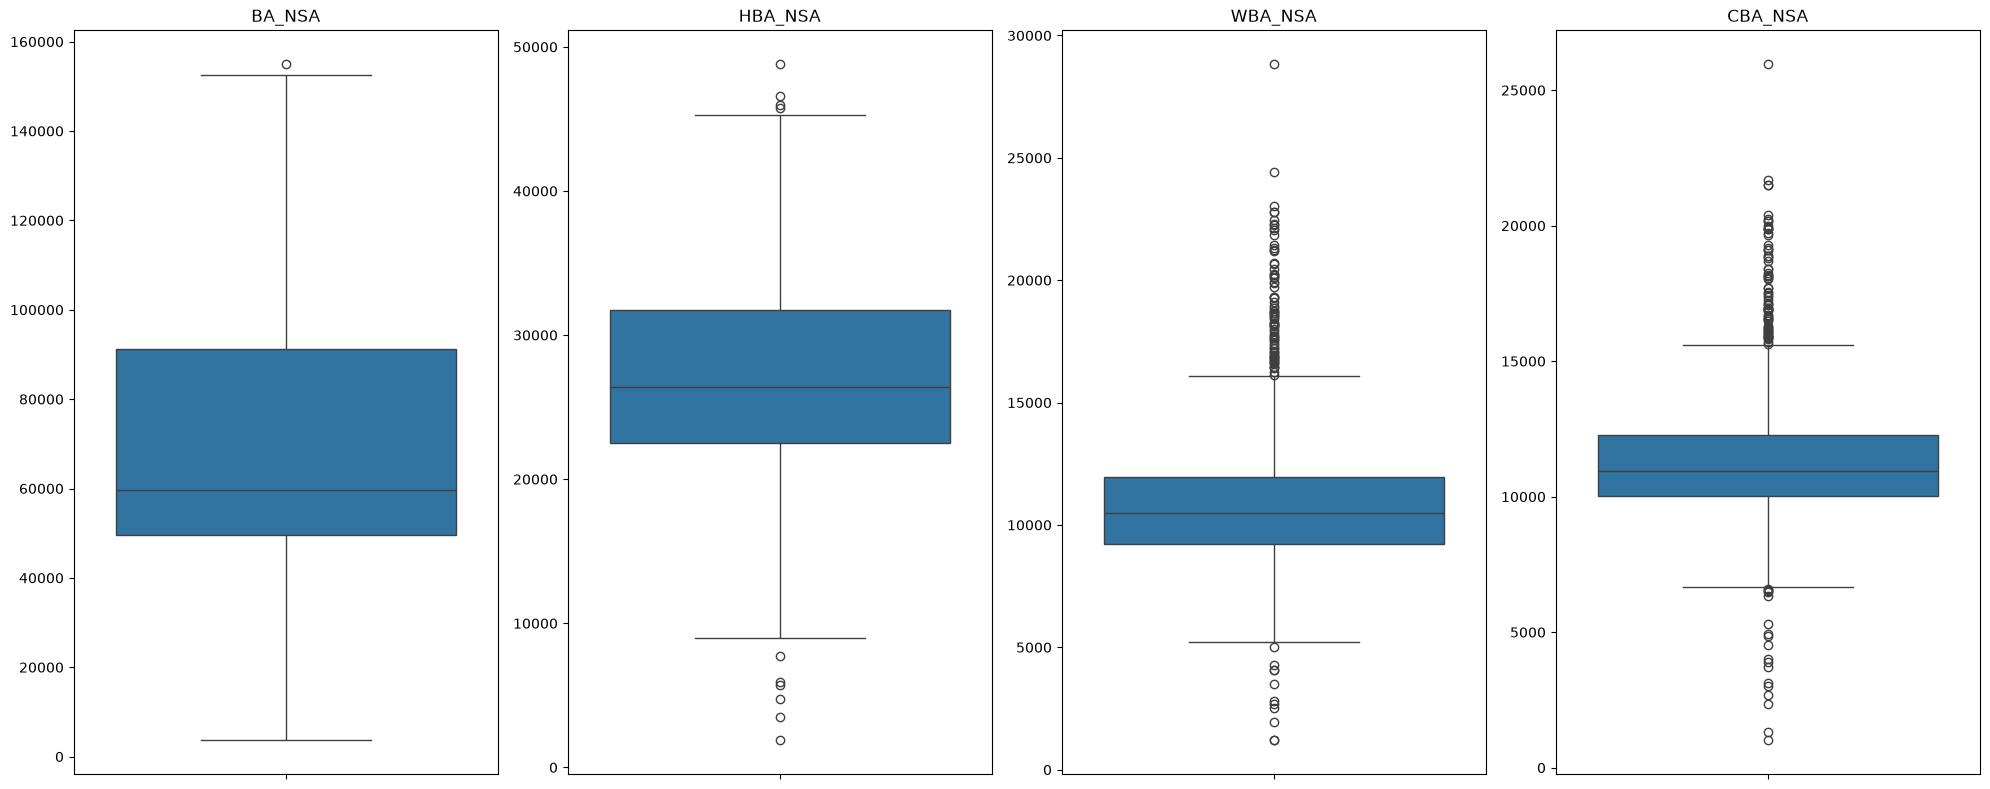

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns, excluding Year and Week
numeric_cols = ["BA_NSA", "HBA_NSA", "WBA_NSA", "CBA_NSA"]

fig, axes = plt.subplots(1, 4, figsize=(20, 8))

for col, ax in zip(numeric_cols, axes.flat):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [75]:
for col in ["BA_NSA", "HBA_NSA", "WBA_NSA", "CBA_NSA"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]
    print(f"Column: {col}, Number of outliers: {len(outliers)}, Number of rows: {len(df)}, Percentage: {len(outliers)/len(df)*100:.2f}%")

Column: BA_NSA, Number of outliers: 1, Number of rows: 1082, Percentage: 0.09%
Column: HBA_NSA, Number of outliers: 10, Number of rows: 1082, Percentage: 0.92%
Column: WBA_NSA, Number of outliers: 87, Number of rows: 1082, Percentage: 8.04%
Column: CBA_NSA, Number of outliers: 90, Number of rows: 1082, Percentage: 8.32%


- BA varies considerably over the observation period, but almost all observations remain within its broad IQR-based boundaries. Its variability is not dominated by numerous isolated extreme values.
- HBA has comparatively few extreme observations.
- WBA high outlier frequency is consistent with its strong right skewness.
- CBA has a central distribution, but observations outside that narrow central range occur relatively frequently.

In [101]:
df["Date"] = (
    pd.to_datetime(df["Year"].astype(str) + "-01-01")
    + pd.to_timedelta((df["Week"] - 1) * 7, unit="D"))

df = df.sort_values("Date")

Why create a Date feature?

The dataset stores time in separate Year and Week columns. Combining them into a single Date feature allows observations to be sorted chronologically and makes it easier to visualize changes over time.

This is important for question 1, which investigates changes in total business applications (`BA_NSA`), and question 5, which examines long-term trends and recurring weekly patterns.

***Preparation Decisions***

Based on the data-quality checks and outlier analysis, the following decisions were made:

**1. Missing Values**

The four year-over-year (`YY_*`) columns each contain 55 missing values (`NaN`). These values are expected due to the unavailability of previous-year comparisons and the reporting-week convention.

Therefore, the missing values are retained, while the `YY_*` columns are excluded from analysis focusing on raw business application counts. No rows are dropped, preserving observations from 2006 and Week 53. This ensures that the complete available historical record remains intact for question 5 (long-term trends).

**2. Outlier Handling**

The IQR method identified statistical outliers in `BA_NSA`, `HBA_NSA`, `WBA_NSA`, and `CBA_NSA`. However, these observations are intentionally retained because unusually high or low business application counts may represent genuine economic fluctuations or reporting-week effects rather than data-entry errors.

Preserving these observations is particularly important for question 1 (changes after 2020) and question 5 (historical trends), as removing extreme values could distort the interpretation of economic changes and recurring weekly patterns.


***Phase 4: Modeling/Analysis***

Descriptive Statistics

In [ ]:
df.describe()

,Year,Week,BA_NSA,HBA_NSA,WBA_NSA,CBA_NSA,YY_BA_NSA,YY_HBA_NSA,YY_WBA_NSA,YY_CBA_NSA
count,1082.000000,1082.000000,1082.000000,1082.000000,1082.000000,1082.000000,1027.000000,1027.000000,1027.000000,1027.000000
mean,2015.878928,26.339187,69627.680222,27353.807763,11003.133087,11293.012939,8.125852,3.935083,-0.469211,0.109562
std,5.996695,14.990793,27324.215456,6735.113760,3044.861412,2549.362507,46.786791,43.147826,38.339325,37.167957
min,2006.000000,1.000000,3650.000000,1880.000000,1200.000000,1010.000000,-88.600000,-89.630000,-90.270000,-87.900000
25%,2011.000000,13.000000,49587.500000,22545.000000,9222.500000,10020.000000,-3.370000,-6.765000,-10.495000,-8.500000
50%,2016.000000,26.000000,59720.000000,26385.000000,10500.000000,10950.000000,3.230000,0.120000,-3.360000,-2.330000
75%,2021.000000,39.000000,91142.500000,31750.000000,11977.500000,12260.000000,10.455000,6.465000,3.160000,3.880000
max,2026.000000,53.000000,155020.000000,48820.000000,28840.000000,25970.000000,1010.400000,923.360000,786.990000,786.260000


On average:
- Approximately 69,628 business applications are recorded per week.
- About 27,354 meet the high-propensity classification.
- Around 11,003 indicate planned wages.
- Around 11,293 originate from corporations.

All four features have a mean greater than their median, but the difference is particularly large for BA_NSA. This suggests that relatively high observations are pulling the mean upward and also made it to have the highest variability.

Skewness

In [ ]:
numeric_df = df.select_dtypes(include="number")

numeric_df.skew()

Year           0.005717
Week           0.018155
BA_NSA         0.794756
HBA_NSA        0.216535
WBA_NSA        1.344328
CBA_NSA        0.940978
YY_BA_NSA     14.272604
YY_HBA_NSA    14.191389
YY_WBA_NSA    12.519659
YY_CBA_NSA    14.160395
dtype: float64

The distribution of BA_NSA has a moderately longer right tail (skewness: 0.79). This suggests that some weeks have substantially higher business application counts than typical weeks.

The year-over-year distributions are highly asymmetric, and their means and standard deviations may be strongly influenced by extreme positive observations.

Histograms

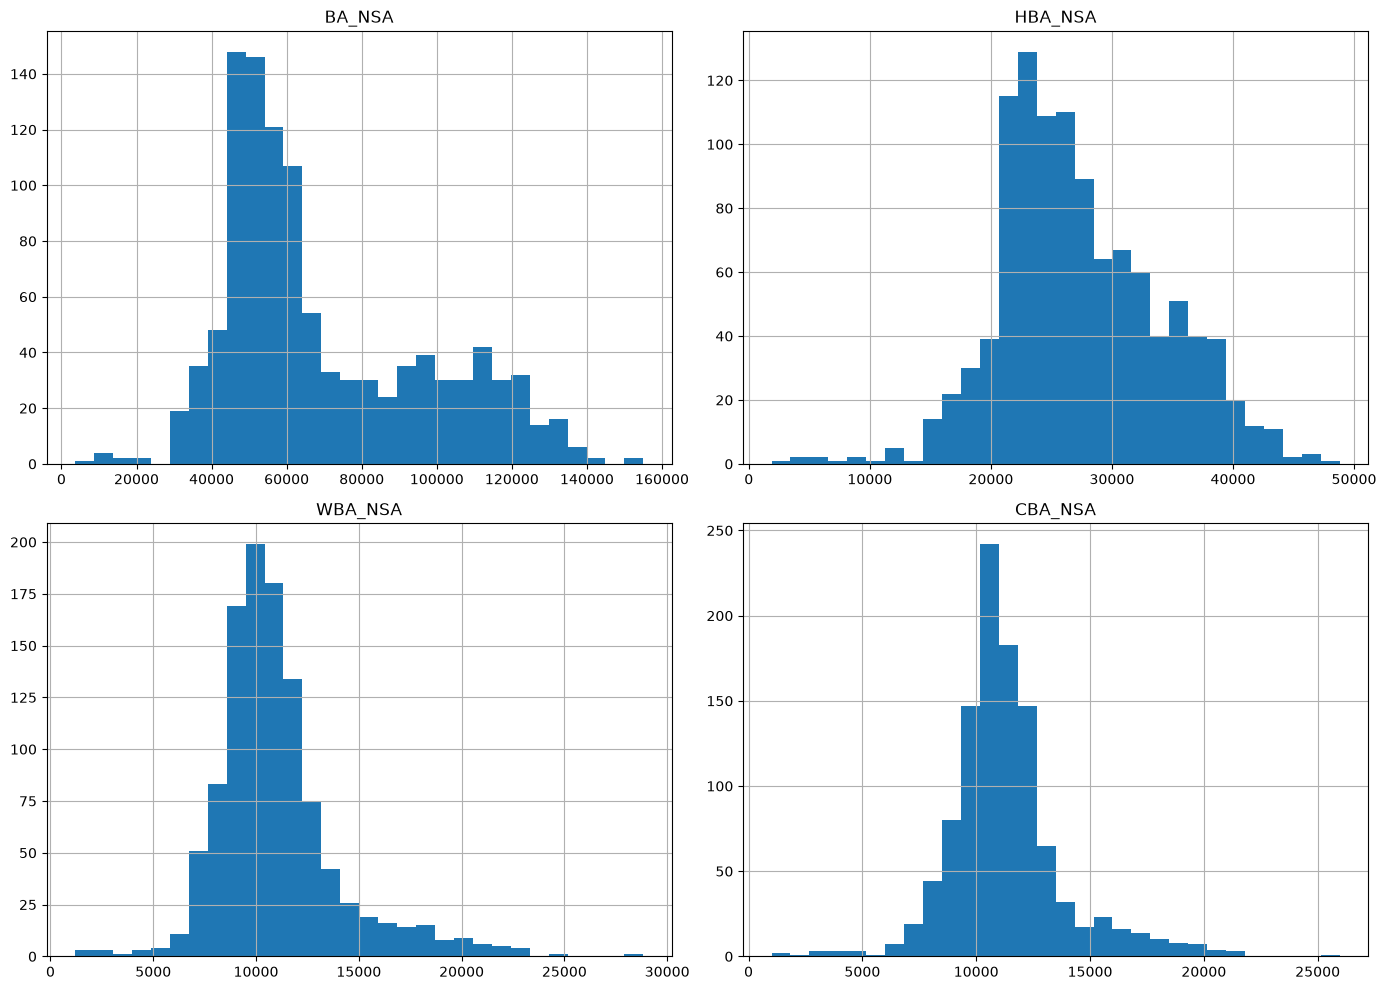

In [ ]:
numeric_cols = ["BA_NSA", "HBA_NSA", "WBA_NSA", "CBA_NSA"]
df[numeric_cols].hist(figsize=(14, 10),bins=30)

plt.tight_layout()
plt.show()

- BA_NSA:
    - A major concentration around 45,000–65,000 applications.
    - Relatively few observations at very low application counts.
- HBA_NSA:
    - A primary concentration around 20,000–30,000, with observations extending on both sides.
    - The most symmetric distribution among the four indicators, suggesting less overall asymmetry in its weekly application counts.
- WBA_NSA:
    - Most observations concentrated within a relatively narrow range.
    - The most positively skewed original indicator.
    - A large proportion of weeks have application counts near 10,000, while a smaller number of weeks have much higher values.
- CBA_NSA:
    - A narrow central peak around 10,000–12,000 applications.
    - Most weeks have similar levels of corporate business applications, while some weeks show substantially higher counts.

Correlation Map

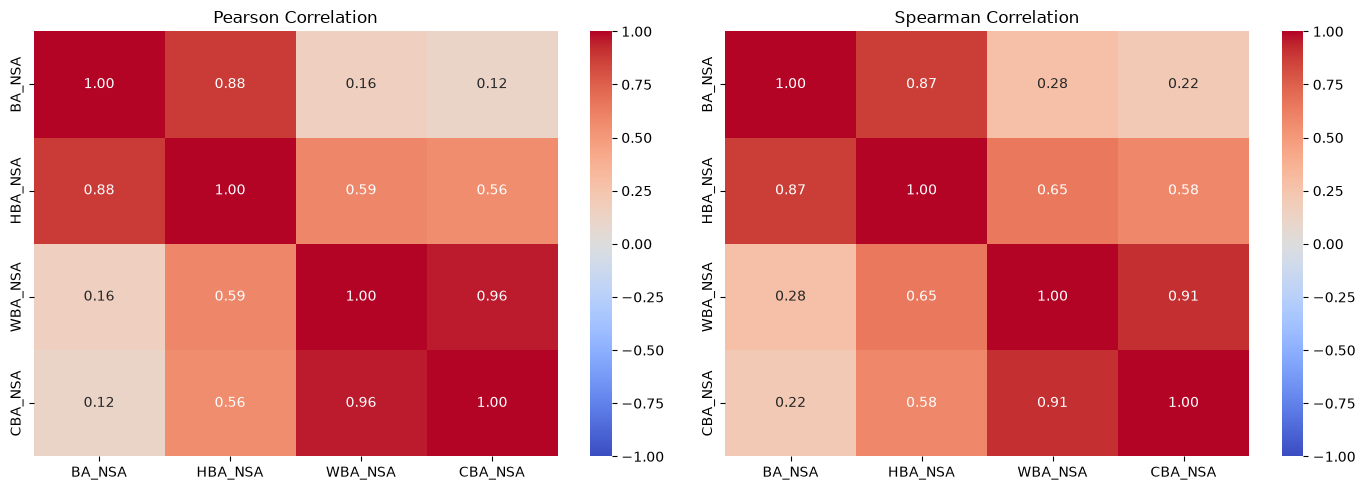

In [ ]:
main_cols = [
    "BA_NSA", "HBA_NSA",
    "WBA_NSA", "CBA_NSA"
]

pearson_corr = df[main_cols].corr(method="pearson")
spearman_corr = df[main_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=axes[0]
)
axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

In [115]:
pairs = [
    ("WBA_NSA", "CBA_NSA"),
    ("BA_NSA", "HBA_NSA"),
    ("BA_NSA", "WBA_NSA"),
    ("BA_NSA", "CBA_NSA")
]

comparison = pd.DataFrame([
    {
        "Feature Pair": f"{x} vs {y}",
        "Pearson": pearson_corr.loc[x, y],
        "Spearman": spearman_corr.loc[x, y]
    }
    for x, y in pairs
])

print(comparison.round(3))

         Feature Pair  Pearson  Spearman
0  WBA_NSA vs CBA_NSA    0.956     0.914
1   BA_NSA vs HBA_NSA    0.879     0.873
2   BA_NSA vs WBA_NSA    0.157     0.276
3   BA_NSA vs CBA_NSA    0.115     0.217


To evaluate the relationships between the four main business application indicators, both Pearson and Spearman correlations were calculated.

Pearson correlation measures the strength of linear relationships, while Spearman correlation evaluates monotonic relationships using ranked observations, making it less sensitive to extreme values.

The initial Pearson analysis revealed strong positive relationships between `WBA_NSA` and `CBA_NSA` (0.96), and between `BA_NSA` and `HBA_NSA` (0.88). In contrast, `BA_NSA` showed weak linear relationships with `WBA_NSA` (0.16) and `CBA_NSA` (0.12).

Comparing these coefficients with Spearman correlations helps assess whether the observed associations remain consistent when the influence of extreme values is reduced.

This analysis supports question 3, which investigates the relationship between wage-planned and corporate business applications, and question 4, which examines the overall relationships among the four indicators.

Feature Relationships

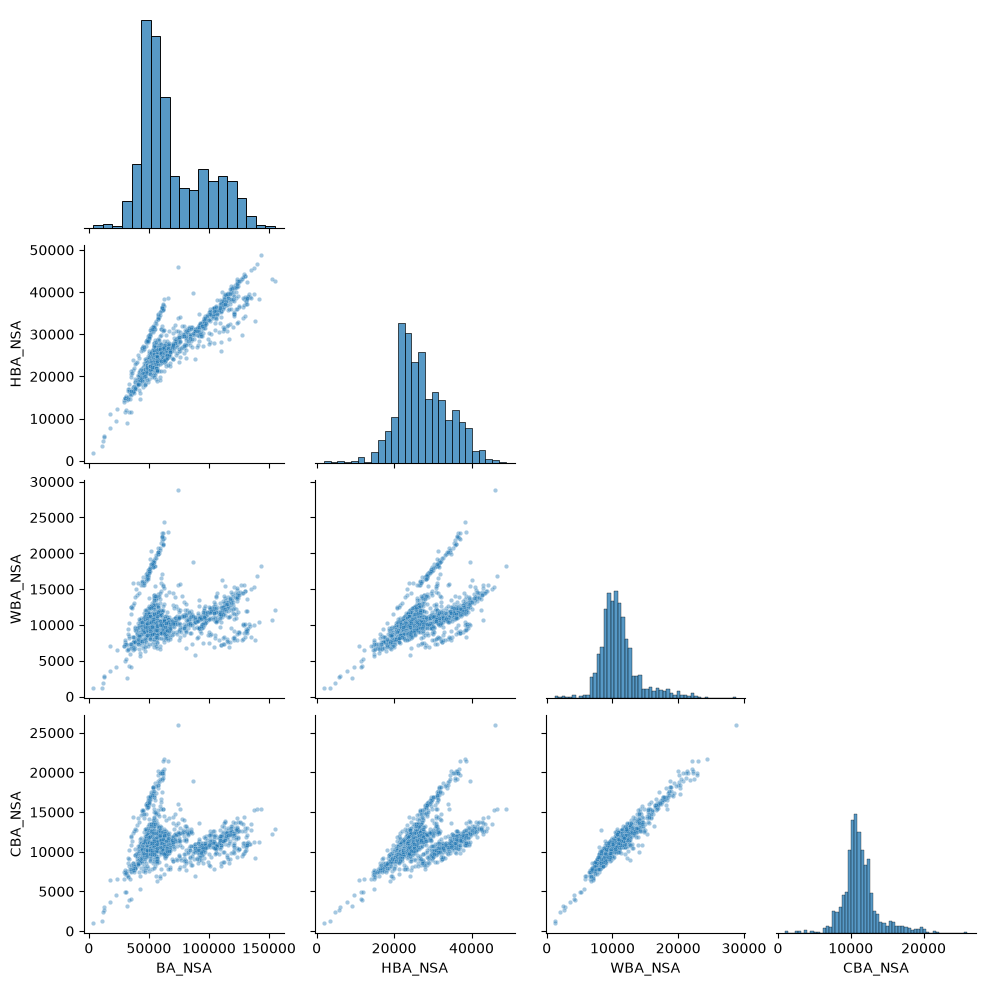

In [77]:
cols = ["BA_NSA", "HBA_NSA", "WBA_NSA", "CBA_NSA"]

sns.pairplot(
    df[cols],
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 10}
)

plt.show()

- A very strong positive relationship exists between WBA and CBA. Weeks with more wage-planned business applications tend to have more corporate business applications.
This interpretation is also supported with 0.96 correlation coefficient (previous step).


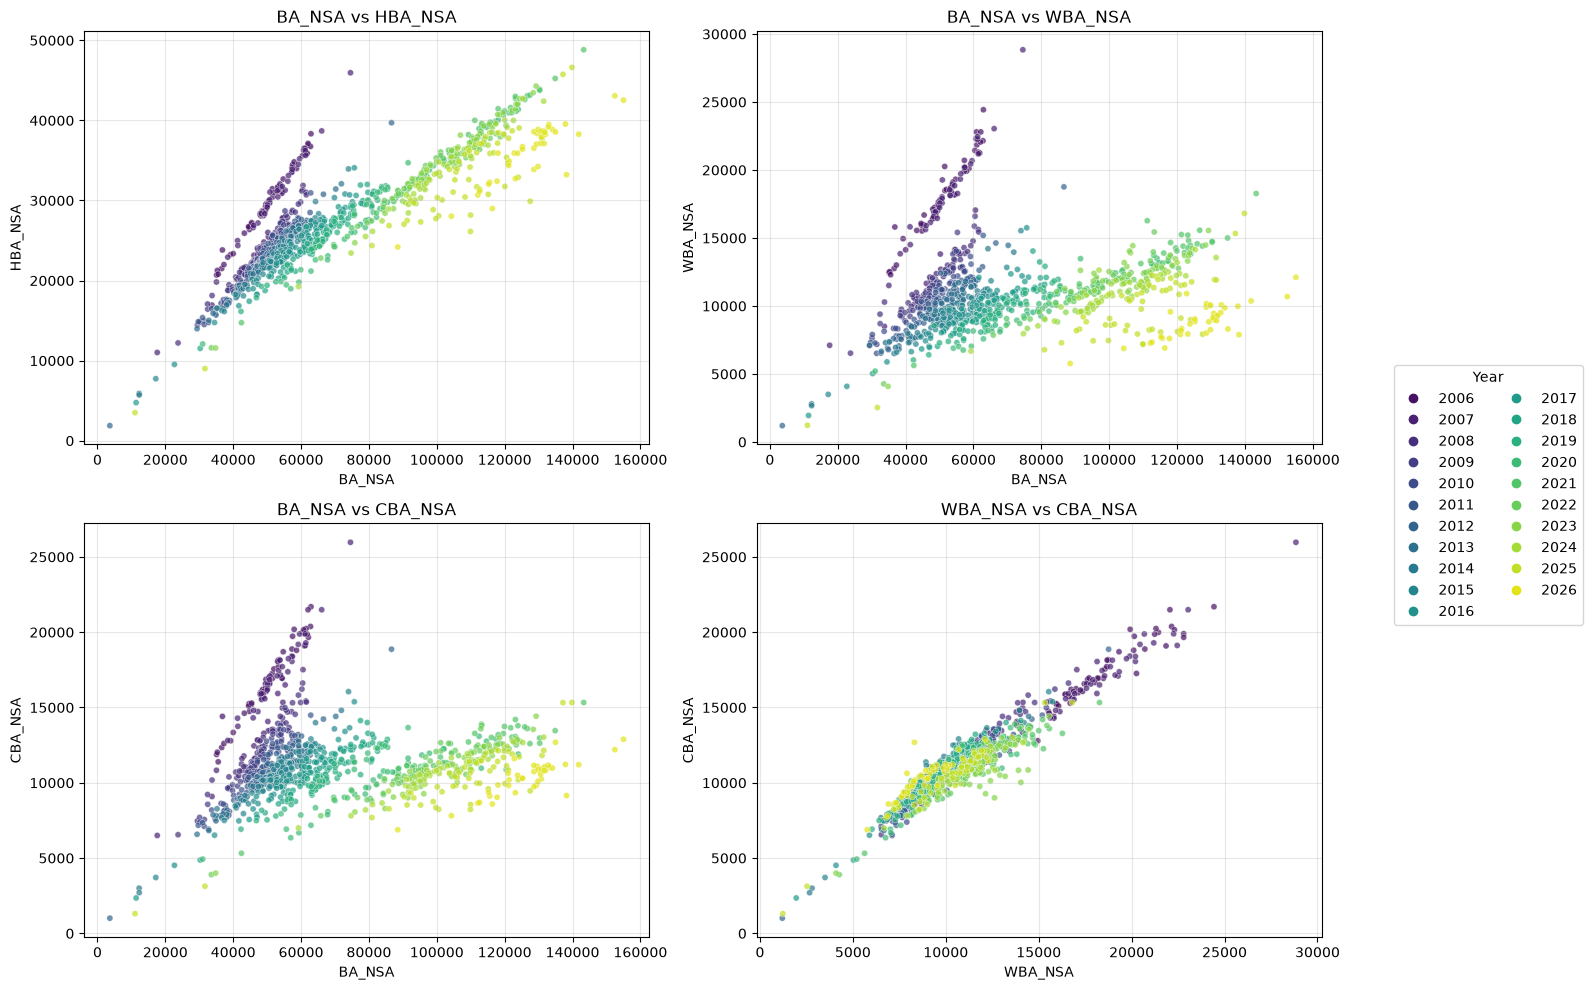

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

pairs = [
    ("BA_NSA", "HBA_NSA"),
    ("BA_NSA", "WBA_NSA"),
    ("BA_NSA", "CBA_NSA"),
    ("WBA_NSA", "CBA_NSA")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

years = sorted(df["Year"].unique())
colors = sns.color_palette("viridis", n_colors=len(years))
palette = dict(zip(years, colors))

for ax, (x, y) in zip(axes.flat, pairs):
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        hue="Year",
        hue_order=years,
        palette=palette,
        alpha=0.7,
        s=20,
        ax=ax,
        legend=False
    )

    ax.set_title(f"{x} vs {y}")
    ax.grid(alpha=0.3)

# Shared legend for all four plots
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=palette[year],
        label=str(year),
        markersize=6
    )
    for year in years
]

fig.legend(
    handles=handles,
    title="Year",
    loc="center left",
    bbox_to_anchor=(0.87, 0.5),
    ncol=2
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

- BA vs. HBA:
    - BA values are mostly concentrated around 35,000–65,000. HBA generally increases as BA increases.
    - 2020–2024: BA frequently reaches 90,000–140,000, while HBA increases less proportionally.
    - 2025–2026: Some weeks have very high BA counts but relatively lower HBA counts than previous years with similar BA levels.
    - Total business applications have generally increased, but high-propensity applications have not always increased at the same rate.
- BA vs. WBA:
    - In earlier years, WBA increases noticeably with BA. It sometimes exceeds 20,000.
    - For later years, BA becomes much larger but WBA remains frequently between approximately 8,000 and 15,000.
    - The share of business applications indicating planned wages appears to have declined over time, despite growth in total applications.
- BA vs. CBA:
    - Newer observations appear to have lower number of corporate business applications than older ones at similar BA levels.
    - The proportion of corporate business applications appears to have declined relative to total applications.
- WBA vs. CBA:
    - Earlier years include more observations at higher WBA and CBA values.
    - Later years are often concentrated around lower WBA and CBA values.
    - Wage-planned applications and corporate applications appear to follow similar temporal dynamics.

Explore Trends

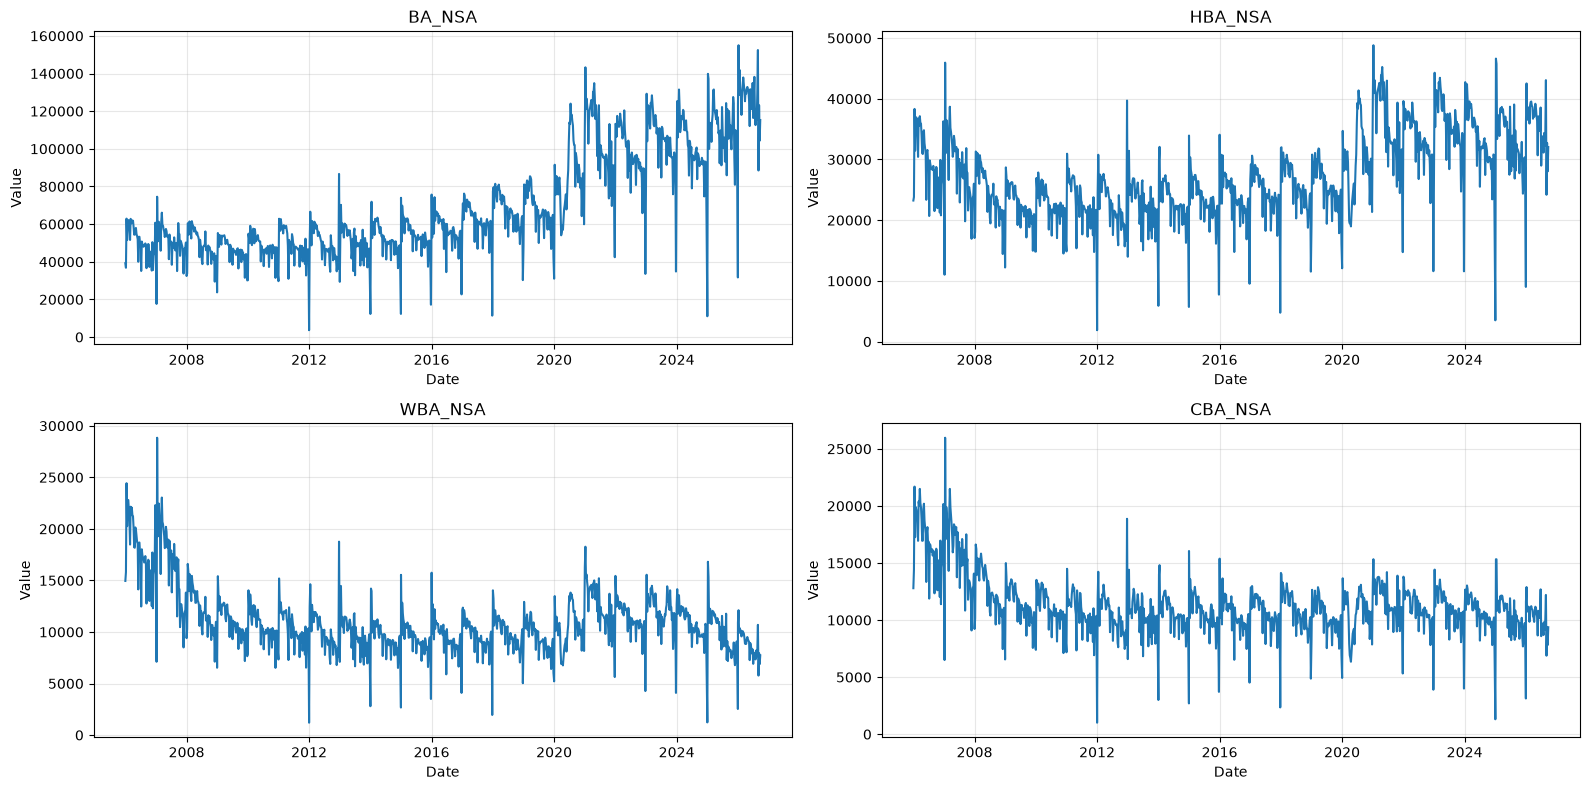

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ["BA_NSA", "HBA_NSA", "WBA_NSA", "CBA_NSA"]

df = df.sort_values("Date")

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

for col, ax in zip(numeric_cols, axes.flat):
    sns.lineplot(
        data=df,
        x="Date",
        y=col,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("Date")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- BA:
        - Total business applications exhibit a substantial upward shift around 2020.
        - BA exhibits recurring short-term fluctuations.
- HBA:
        - HBA experienced a decline during the earlier years before recovering.
        - Growth in HBA appears smaller proportionally than growth in BA.
- WBA and CBA:
        - Even though total business applications became much more numerous after 2020, planned-wage applications and corporate applications did not increase persistently.
        - They exhibit very similar long-term trajectories.


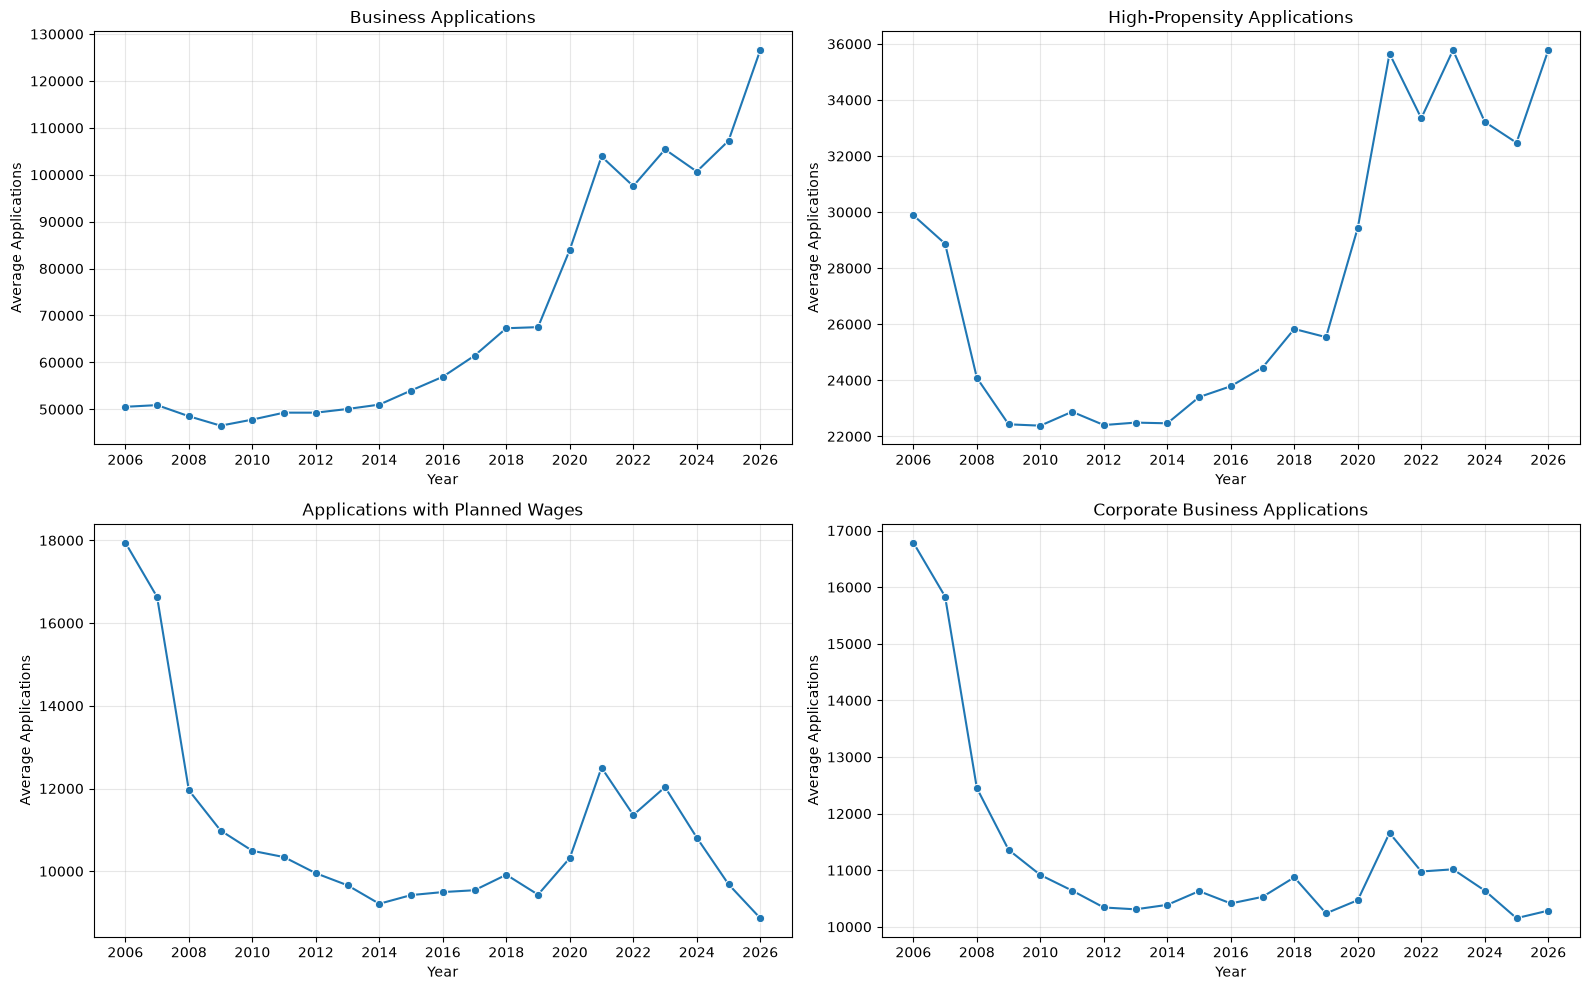

In [123]:
BA_annual = df.groupby("Year")["BA_NSA"].mean().reset_index(name="BA_Annual")
HBA_annual = df.groupby("Year")["HBA_NSA"].mean().reset_index(name="HBA_Annual")
WBA_annual = df.groupby("Year")["WBA_NSA"].mean().reset_index(name="WBA_Annual")
CBA_annual = df.groupby("Year")["CBA_NSA"].mean().reset_index(name="CBA_Annual")

annual_data = [
    (BA_annual, "BA_Annual", "Business Applications"),
    (HBA_annual, "HBA_Annual", "High-Propensity Applications"),
    (WBA_annual, "WBA_Annual", "Applications with Planned Wages"),
    (CBA_annual, "CBA_Annual", "Corporate Business Applications")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (data, column, title) in zip(axes.flat, annual_data):
    sns.lineplot(
        data=data,
        x="Year",
        y=column,
        marker="o",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel("Average Applications")
    ax.set_xticks(range(2006, 2027, 2))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [116]:
import pandas as pd
import numpy as np

df["Period"] = np.where(
    df["Year"] < 2020,
    "Pre-2020",
    "2020 and Later"
)
summary = df.groupby("Period")["BA_NSA"].agg(
    mean = lambda x: x.mean(),
    median = lambda x: x.median(),
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

summary["IQR"] = summary["Q3"] - summary["Q1"]

print(summary.round(2))

                     mean    median       Q1        Q3      IQR
Period                                                         
2020 and Later  102795.11  104385.0  91602.5  116895.0  25292.5
Pre-2020         53634.62   53145.0  47180.0   60455.0  13275.0


To For better answering question 1, `BA_NSA` were divided into two periods: 
- Pre-2020 (2006–2019)
- 2020 and Later (2020–2026).

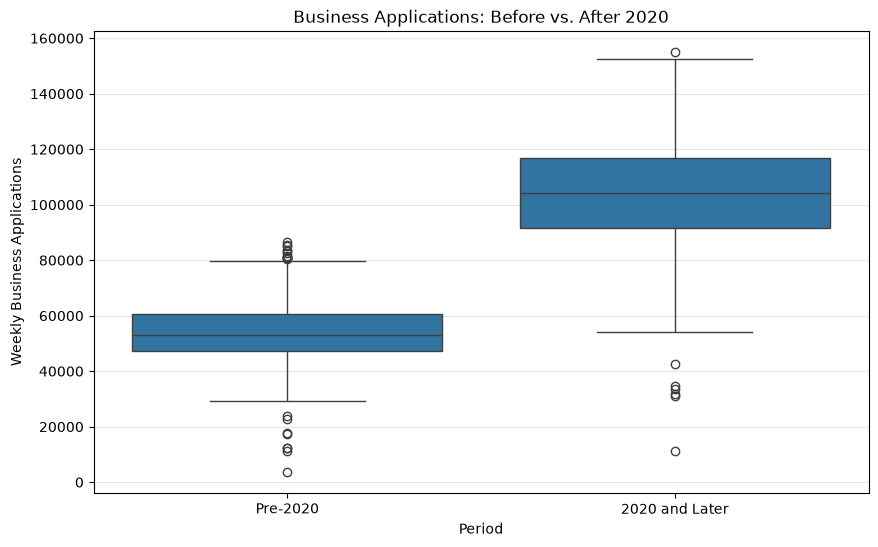

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Period",
    y="BA_NSA",
    order=["Pre-2020", "2020 and Later"]
)

plt.title("Business Applications: Before vs. After 2020")
plt.xlabel("Period")
plt.ylabel("Weekly Business Applications")
plt.grid(axis="y", alpha=0.3)

plt.show()

These statistics help determine whether the increase in business applications after 2020 reflects a broad shift in weekly application levels rather than a small number of unusually high observations.

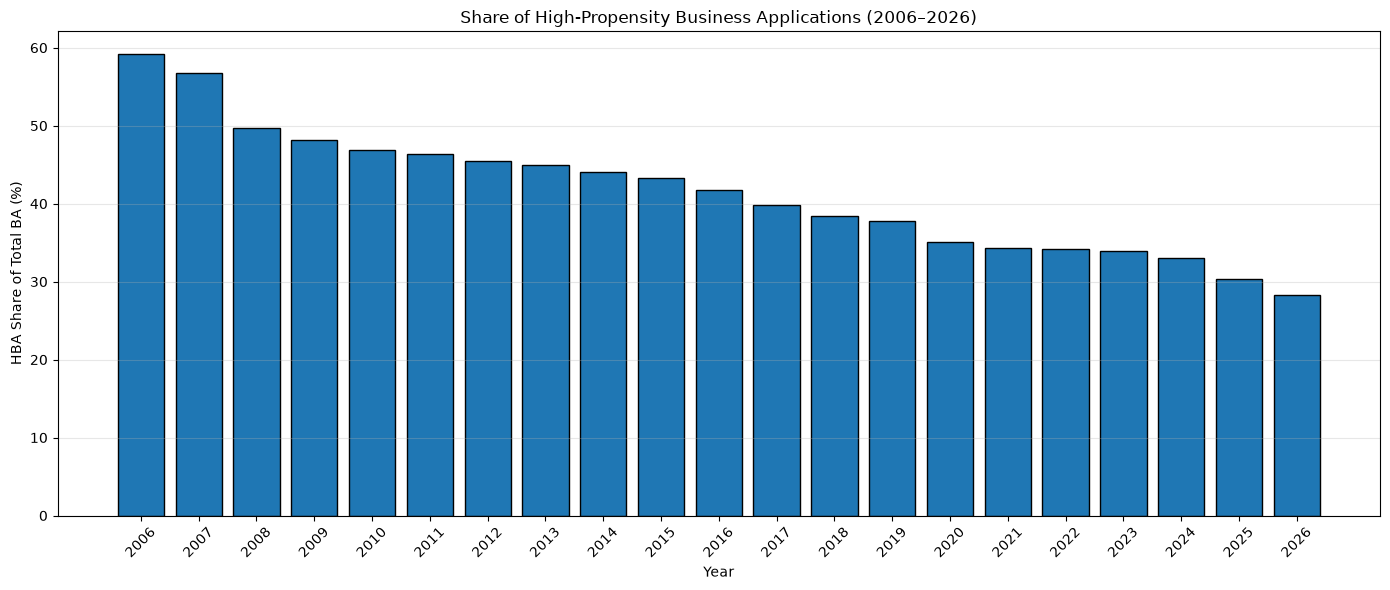

In [121]:
#compute share metric for `BA_NSA` and `HBA_NSA` for each year

import matplotlib.pyplot as plt
import numpy as np

share = (df.groupby("Year")["HBA_NSA"].sum() / df.groupby("Year")["BA_NSA"].sum()) * 100
share = share.loc[2006:2026]

plt.figure(figsize=(14, 6))
plt.bar(share.index,share.values,edgecolor="black")

plt.title("Share of High-Propensity Business Applications (2006–2026)")
plt.xlabel("Year")
plt.ylabel("HBA Share of Total BA (%)")
plt.xticks(np.arange(2006, 2027), rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

***Phase 5: Evaluation***

Question 1: How did `BA_NSA` change after 2020?

`BA_NSA` increased significantly after 2020, with weekly business applications frequently exceeding 100,000 compared to approximately 40,000–80,000 in earlier years. This increase remained relatively persistent in subsequent years.
Based on statistics computed in phase 4, average number of business applications after 2020 equals 102,795 while before this period, it was around 53,000.

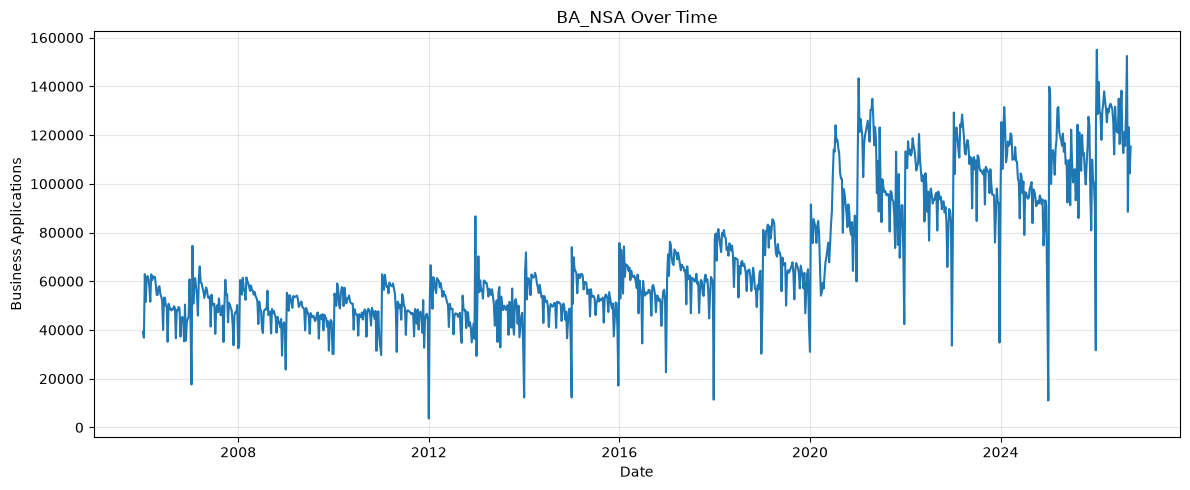

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

df = df.sort_values("Date")

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=df,
    x="Date",
    y="BA_NSA",
    ax=ax
)

ax.set_title("BA_NSA Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Business Applications")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Question 2: Did `HBA_NSA` grow proportionally with `BA_NSA`?

No. Although `HBA_NSA` also increased after 2020, its growth was less pronounced than that of `BA_NSA`. The plot related to share of HBA out of all applications suggest that high-propensity applications represent a smaller proportion of total applications in recent years. Actually, `HBA_NSA` as a downward trend during this period from 2006 to 2026.

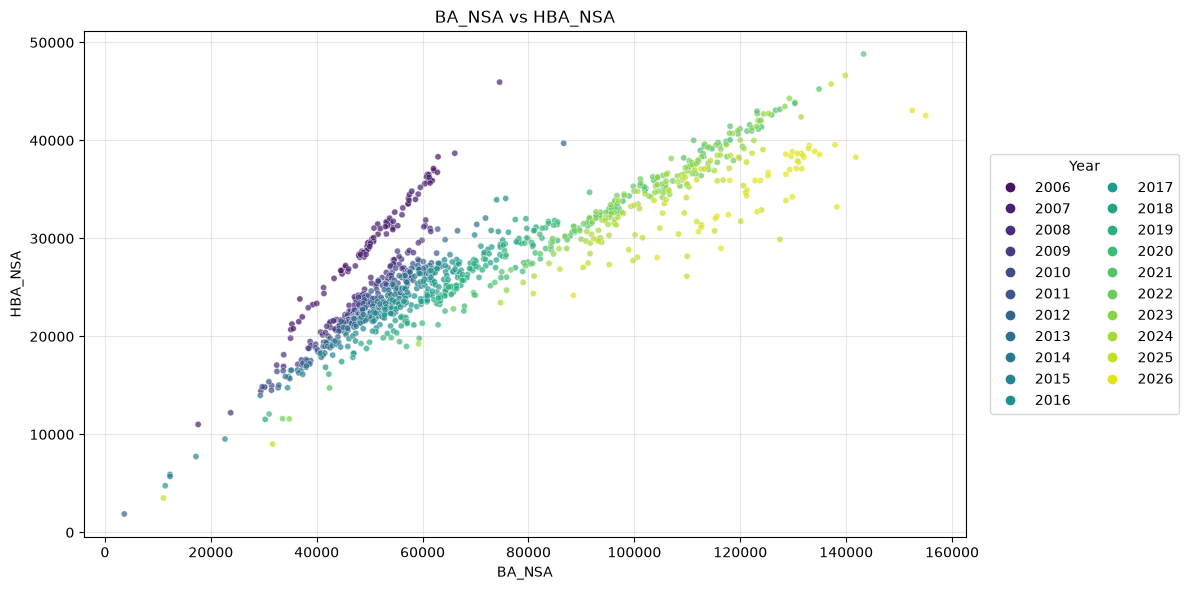

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

x = "BA_NSA"
y = "HBA_NSA"

years = sorted(df["Year"].unique())
colors = sns.color_palette("viridis", n_colors=len(years))
palette = dict(zip(years, colors))

fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x=x,
    y=y,
    hue="Year",
    hue_order=years,
    palette=palette,
    alpha=0.7,
    s=20,
    ax=ax,
    legend=False
)

ax.set_title(f"{x} vs {y}")
ax.set_xlabel(x)
ax.set_ylabel(y)
ax.grid(alpha=0.3)

# Create legend for each year
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=palette[year],
        label=str(year),
        markersize=6
    )
    for year in years
]

ax.legend(
    handles=handles,
    title="Year",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=2
)

plt.tight_layout()
plt.show()

Question 3: How strongly are `WBA_NSA` and `CBA_NSA` related?

They have a very strong positive correlation (r = 0.96). Their scatterplot shows a nearly linear relationship, indicating that both indicators tend to increase and decrease together.

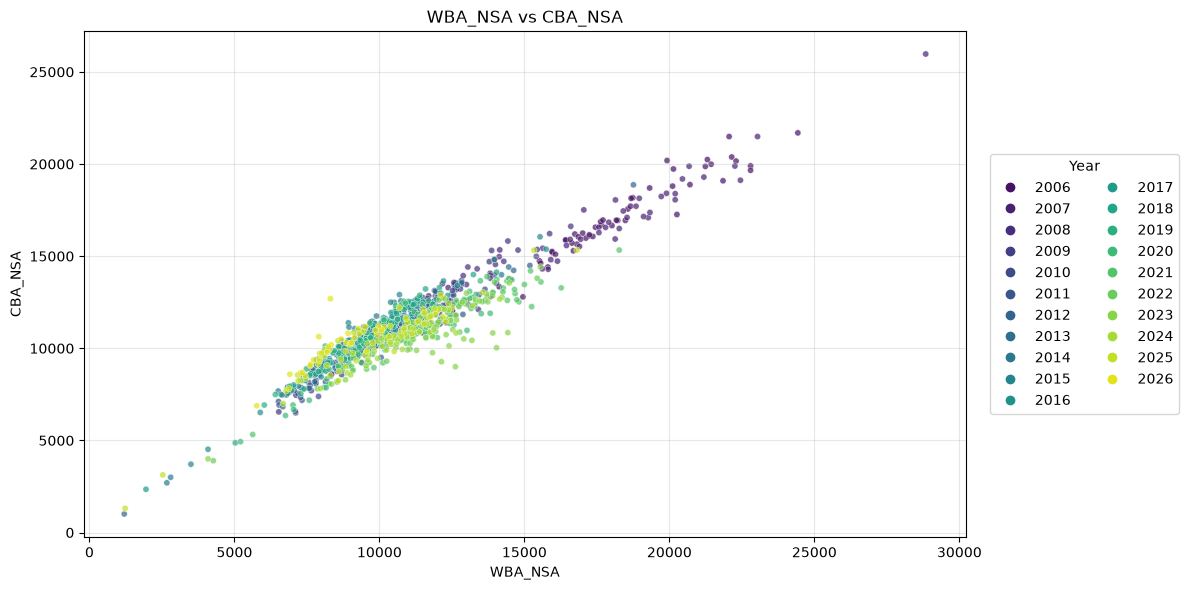

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

x = "WBA_NSA"
y = "CBA_NSA"

years = sorted(df["Year"].unique())
colors = sns.color_palette("viridis", n_colors=len(years))
palette = dict(zip(years, colors))

fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x=x,
    y=y,
    hue="Year",
    hue_order=years,
    palette=palette,
    alpha=0.7,
    s=20,
    ax=ax,
    legend=False
)

ax.set_title(f"{x} vs {y}")
ax.set_xlabel(x)
ax.set_ylabel(y)
ax.grid(alpha=0.3)

# Create legend for each year
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=palette[year],
        label=str(year),
        markersize=6
    )
    for year in years
]

ax.legend(
    handles=handles,
    title="Year",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=2
)

plt.tight_layout()
plt.show()

Question 4: Are `BA_NSA`,`HBA_NSA`,`WBA_NSA` and `CBA_NSA` correlated strongly?

Not all of them. BA_NSA and HBA_NSA are strongly correlated (r = 0.88), as are `WBA_NSA` and `CBA_NSA` (r = 0.96). However, `BA_NSA` has weak correlations with `WBA_NSA` (r = 0.16) and `CBA_NSA` (r = 0.12), suggesting different patterns of change.


Question 5: What long-term trends and recurring weekly patterns appear in these four business application indicators between 2006 and 2026?

Based on Line plots in phase 4, total business applications show an upward trend with subtle fluctuations throught 2022-2025. `HBA_NSA` also increases but less proportionally, while `WBA_NSA` and `CBA_NSA` declined during earlier years and showed limited sustained growth afterward. The data also exhibits recurring weekly fluctuations and occasional extreme spikes, suggesting possible seasonal and reporting effects.

##### Limitations & Next Steps

Although the analysis revealed meaningful trends in U.S. business applications, several limitations should be considered:

1. **Seasonality:** The dataset is Not Seasonally Adjusted (NSA), meaning weekly observations may be influenced by seasonal patterns, holidays, and reporting-calendar differences, including Week 53. Future analysis could apply seasonal decomposition to distinguish long-term trends from recurring fluctuations.

2. **Incomplete 2026 Data:** The dataset does not cover the full year of 2026. Therefore, annual comparisons involving 2026 should be interpreted cautiously, as partial-year observations may not represent the entire year's activity.

3. **Correlation vs. Causation:** The strong correlations observed between business application indicators describe statistical associations, not causal relationships. Further analysis would be required to identify the factors driving these patterns.

**Next Steps:** Future work could focus on seasonally adjusted comparisons, investigating extreme reporting weeks, and examining how the proportions of high-propensity, planned-wage, and corporate applications have evolved over time.